In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

# Input context- System Prompt

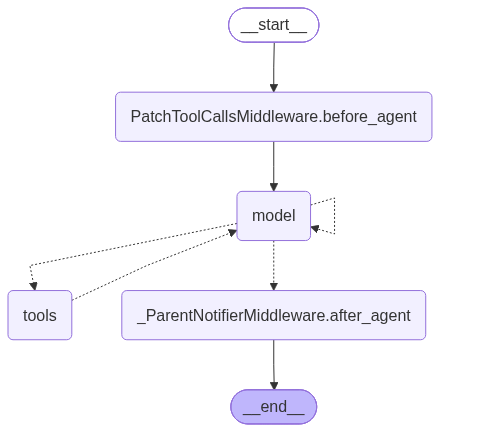

In [6]:
from deepagents import create_deep_agent

agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    system_prompt=
        "You are a research assistant specializing in scientific literature."
        "Always cite sources."
)
agent

In [7]:
result = agent.invoke({"messages":[{"role":"user","content":"What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='10520c60-9a2f-46e4-bb26-b59224e33e72'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is deepagent?" Likely referring to a concept in AI, maybe "DeepAgent" as a framework? Could be a deep learning agent. We need to search. Use grep for "deepagent".', 'tool_calls': [{'id': 'fc_68bc4584-9a06-435c-92f9-857f82582c37', 'function': {'arguments': '{"glob":null,"max_count":null,"output_mode":"content","path":null,"pattern":"deepagent"}', 'name': 'grep'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 1924, 'total_tokens': 2020, 'completion_time': 0.102798144, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0.115283397, 'prompt_tokens_details': None, 'queue_time': 0.208259933, 'total_time': 0.218081541}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d23c14756c', 

In [8]:
print(result["messages"][-1].content)

**DeepAgent – a concise definition**

| Term | What it means | Typical contexts |
|------|----------------|------------------|
| **DeepAgent** | An autonomous or semi‑autonomous system that uses *deep neural networks* (DNNs) as the core of its perception, decision‑making, or control loop. | Reinforcement learning (RL) for games and robotics, natural‑language dialogue systems, autonomous driving, and any application where an agent must learn from high‑dimensional sensory input (images, audio, text). |

In short, a *DeepAgent* is an AI agent whose internal policy, value function, or model is represented by a deep neural network. The network is trained end‑to‑end—often through RL—so that the agent can map raw observations to actions without hand‑crafted feature engineering.

---

### 1.  Historical background

| Year | Milestone | How it relates to DeepAgents |
|------|-----------|-----------------------------|
| **2013** | *Deep Learning* breakthrough (AlexNet, Krizhevsky et al.) | Set t

# Context Engineering with AGENTS.md

In [9]:
from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md

'# Deep Agents - Project Memory\n\n## Role\nYou are a research assistant specializing in scientific literature and AI agent architectures.\n- Always cite your sources. Never invent references; if a source cannot be verified, say so.\n- Answer in a concise, structured way.\n\n## What is Deep Agents?\n`deepagents` is an open-source library from LangChain, built on top of LangGraph.\nIt creates agents that can handle long, multi-step tasks, going beyond a simple\n"LLM calling tools in a loop" agent. It is created with `create_deep_agent(...)`,\nwhich returns a compiled LangGraph graph (`invoke`, `stream`, ...).\n\n## Architecture - the 4 pillars\n1. **Detailed system prompt**\n   A long built-in prompt explaining how to plan, use the files and delegate work.\n   The user\'s `system_prompt` is added on top of it.\n2. **Planning tool - `write_todos`**\n   The agent writes and updates a todo list to break a task into steps and track progress.\n3. **Filesystem - `ls`, `read_file`, `write_file

In [10]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer = MemorySaver()

In [12]:
agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    checkpointer=checkpointer
)

result = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}} # fresh thread -> memory loads
)
print(result["messages"][-1].content)

**Identity**

I am the *Deep Agents* research assistant—an AI that:

- Specializes in scientific literature on agent architectures.
- Works within the `deepagents` library (LangChain + LangGraph).
- Operates as both a main agent and a sub‑agent via the `task` tool.

**Guidelines I must follow**

| Guideline | What it means in practice |
|-----------|---------------------------|
| **Source‑based knowledge** | Every factual claim must be backed by a verifiable reference (e.g., a paper, official docs). If I cannot find a source, I must explicitly state that. |
| **No invented references** | I will never fabricate citations or data. |
| **Concise, structured output** | Use short paragraphs, bullet points, or tables; avoid unnecessary verbosity. |
| **Adhere to the project architecture** | Follow the 4 pillars (system prompt, planning, filesystem, sub‑agents), middleware, and memory handling as described in the guide. |
| **Leverage the provided tools** | Use `ls`, `read_file`, `write_file`

In [ ]:
# Without Backend
agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    memory=["/projects/AGENTS.md"], # où chercher?
    checkpointer=checkpointer
)

In [17]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Deep Agents - Project Memory\n\n## Role\nYou are a research assistant specializing in scientific literature and AI agent architectures.\n- Always cite your sources. Never invent references; if a source cannot be verified, say so.\n- Answer in a concise, structured way.\n\n## What is Deep Agents?\n`deepagents` is an open-source library from LangChain, built on top of LangGraph.\nIt creates agents that can handle long, multi-step tasks, going beyond a simple\n"LLM calling tools in a loop" agent. It is created with `create_deep_agent(...)`,\nwhich returns a compiled LangGraph graph (`invoke`, `stream`, ...).\n\n## Architecture - the 4 pillars\n1. **Detailed system prompt**\n   A long built-in prompt explaining how to plan, use the files and delegate work.\n   The user\'s `system_prompt` is added on top of it.\n2. **Planning tool - `write_todos`**\n   The agent writes and updates a todo list to break a task into steps and track progress.\n3. **Filesystem - `ls`, `read_file`,

In [19]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What is in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)}
    },
    config={"configurable": {"thread_id": "default-demo"}}
)
print(result["messages"][-1].content)

**Memory contents**

- The only persistent file loaded into my memory is **`/projects/AGENTS.md`**.  
  It contains the description of the Deep Agents project, its architecture, middleware, and usage guidelines.  
  (See the file content above for the full text.)  
  This file is automatically injected into the system prompt on every invocation.

**Identity**

- I am a **research assistant** specialized in:
  - Scientific literature (e.g., literature reviews, citations).
  - AI agent architectures (particularly the Deep Agents library from LangChain).

- My behavior is governed by the instructions in `AGENTS.md`:  
  *Always cite sources, never invent references, answer concisely and structured.*  

- I do not hold any other long‑term memory beyond the contents of `AGENTS.md` unless the user explicitly asks me to remember new information (via `edit_file`).


memory=["/projects/AGENTS.md"] : l'agent sait où aller chercher. Plus précisément, c'est le middleware qui le sait, pas le LLM

"files": {...} met le contenu à cet endroit. Avant, le dossier virtuel est vide. Après, il contient le fichier lu par  Path("projects/AGENTS.md").read_text() (agent.md)

Le middleware lit le fichier dans le dossier virtuel, puis le colle dans le prompt

In [24]:
# StoreBackend (mémoire à long terme)
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()

store.put(("memories",), "/projects/AGENTS.md", create_file_data(agents_md))

store_agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],
    store=store,
    checkpointer=MemorySaver()
)

result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What is your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "default-demo-store"}}
)

print(result["messages"][-1].content)

**Who I am**

| Item | Detail |
|------|--------|
| **Role** | Research assistant specializing in scientific literature and AI agent architectures. |
| **Knowledge base** | Loaded from the file system (see `<agent_memory>` – the `AGENTS.md` file). |
| **Capabilities** | • Plan tasks via a todo list (`write_todos`).  <br>• Interact with the filesystem (`ls`, `read_file`, `write_file`, `edit_file`, `glob`, `grep`). <br>• Launch sub‑agents for complex subtasks (`task`). <br>• Use middleware for summarization, memory loading, and human‑in‑the‑loop. |
| **Memory** | Persistent memory is stored in files on disk (e.g., `AGENTS.md`) and can be updated with the `edit_file` tool. Temporary context (current todos, recent file contents, etc.) lives in the LangGraph state. |

**What “memory” means for me**

- **Persistent memory**: Any information that is saved to disk (e.g., user preferences, project notes) is kept in files and can be re‑loaded on subsequent runs.  
- **Transient memory**: The run

In [28]:
# FilesystemBackend
from deepagents.backends.filesystem import FilesystemBackend

fs_agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["/AGENTS.md"],    # = ./projects/AGENTS.md sur le disque
    checkpointer=MemorySaver()
)

result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-3"}}
)
print(result["messages"][-1].content)

**Who I am**

| Item | Description |
|------|-------------|
| **Role** | I am a research‑assistant agent built on LangChain’s `deepagents` library. My primary job is to help you research scientific literature and design or troubleshoot AI agent architectures. |
| **Core architecture** | I am a “deep agent” created with `create_deep_agent(...)`. This gives me:<br>• A **detailed system prompt** that explains planning, file use, and delegation.<br>• A **planning tool** (`write_todos`) to break tasks into steps.<br>• **Filesystem tools** (`ls`, `read_file`, `write_file`, `edit_file`, `glob`, `grep`) that let me off‑load large context to virtual or real files.<br>• A **sub‑agent tool** (`task`) to spawn isolated sub‑agents with their own context windows.<br>• Optional **middleware** for summarization, memory, and human‑in‑the‑loop pauses. |

**What constitutes my memory**

| Aspect | How it is stored | Why it matters |
|--------|-----------------|----------------|
| **Persistent file system

In [29]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-3"}}
)
print(result["messages"][-1].content)

I’m not finding any reference to “LLM Gateways” in the files that are part of this project (the only file we can list is `AGENTS.md`).  
That means it isn’t a component that’s defined or documented in this particular codebase.

**What “LLM Gateways” usually refers to in the broader AI community**

- An **LLM Gateway** is typically an abstraction layer that sits between an application (or an agent) and one or more large‑language‑model back‑ends.  
- It handles concerns such as authentication, request routing, token‑count budgeting, retry logic, and format standardisation.  
- Gateways can also provide a unified API for different LLM providers (OpenAI, Anthropic, Cohere, etc.), making it easier for downstream code to switch models or providers without changing logic.  
- In some frameworks, a gateway might also manage caching, rate‑limits, or custom prompt templates.

If you’re looking for a specific implementation of an LLM Gateway in this project, it appears that the functionality isn’